Airbnb Listings & Reviews

In [6]:
#Import/Open the Listings.csv file
import pandas as pd
import numpy as np
import seaborn as sns

In [7]:
listings = pd.read_csv(r"C:\Users\User\Downloads\Airbnb+Data\Airbnb Data\Listings.csv",encoding="ISO-8859-1",low_memory=False ,parse_dates=["host_since"])
listings

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
0,281420,"Beautiful Flat in le Village Montmartre, Paris",1466919,2011-12-03,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
1,3705183,39 mÃÂ² Paris (Sacre CÃ âur),10328771,2013-11-29,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
2,4082273,"Lovely apartment with Terrace, 60m2",19252768,2014-07-31,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
3,4797344,Cosy studio (close to Eiffel tower),10668311,2013-12-17,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
4,4823489,Close to Eiffel Tower - Beautiful flat : 2 rooms,24837558,2014-12-14,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279707,38338635,Appartement T2 neuf prÃÂ¨s du tram T3a Porte ...,31161181,2015-04-13,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,1,7,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
279708,38538692,Cozy Studio in Montmartre,10294858,2013-11-27,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,7,15,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
279709,38683356,Nice and cosy mini-appartement in Paris,2238502,2012-04-27,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,6,30,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
279710,39659000,Charming apartment near Rue Saint Maur / Oberk...,38633695,2015-07-16,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,3,18,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f


In [28]:
#Filter the data down to rows where the city is Paris, and keep only the columns ‘host_since’, ‘neighbourhood’, ‘city’, ‘accommodates’, and ‘price’
listings_Paris = listings[listings['city'] == "Paris"]

listings_Paris = listings_Paris[['host_since','neighbourhood','city','accommodates','price']]

In [30]:
listings_Paris.info()

<class 'pandas.core.frame.DataFrame'>
Index: 64690 entries, 0 to 279711
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   host_since     64657 non-null  datetime64[ns]
 1   neighbourhood  64690 non-null  object        
 2   city           64690 non-null  object        
 3   accommodates   64690 non-null  int64         
 4   price          64690 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 3.0+ MB


In [49]:
#QA the Paris listings data: check for missing values, and calculate the minimum, maximum, and average for each numeric field
listings_Paris.describe()


,host_since,accommodates,price
count,64657,64690.000000,64690.000000
mean,2015-11-01 11:06:05.528867584,3.037997,113.096445
min,2008-08-30 00:00:00,0.000000,0.000000
25%,2014-03-09 00:00:00,2.000000,59.000000
50%,2015-07-07 00:00:00,2.000000,80.000000
75%,2017-05-29 00:00:00,4.000000,120.000000
max,2021-02-07 00:00:00,16.000000,12000.000000
std,NaN,1.588766,214.433668


In [53]:
listings_Paris.isna().sum()

host_since       33
neighbourhood     0
city              0
accommodates      0
price             0
dtype: int64

In [59]:
listings_Paris[(listings_Paris["accommodates"] == 0) & (listings_Paris["price"] == 0)].count()

host_since       54
neighbourhood    54
city             54
accommodates     54
price            54
dtype: int64

In [73]:
#Create a table named paris_listings_neighbourhood that groups Paris listings by 'neighbourhood' and calculates the mean price (sorted low to high)
paris_listings_neighbourhood = (
   listings_Paris
    .groupby("neighbourhood")[["price"]]
    .mean()
    .sort_values(by="price", ascending=True)
    .reset_index()
)

# View the result
paris_listings_neighbourhood

,neighbourhood,price
0,Menilmontant,74.942257
1,Buttes-Chaumont,82.690182
2,Buttes-Montmartre,87.209479
3,Reuilly,89.058402
4,Popincourt,90.559459
5,Gobelins,98.110184
6,Observatoire,101.866801
7,Batignolles-Monceau,102.612702
8,Enclos-St-Laurent,102.967156
9,Vaugirard,106.831330


In [75]:
paris_listings_neighbourhood.tail()

,neighbourhood,price
15,Luxembourg,155.638639
16,Palais-Bourbon,156.856578
17,Passy,161.144635
18,Louvre,175.379972
19,Elysee,210.536765


In [79]:
#Find the name of the most expensive neighborhood

most_expensive_neighbourhood = (
    paris_listings_neighbourhood
    .sort_values(by="price", ascending=False)
    .iloc[0]["neighbourhood"]
)

most_expensive_neighbourhood

'Elysee'

In [83]:
# Filter, group by accommodates, calculate mean price, and sort
paris_listings_accommodations = (
    listings_Paris[listings_Paris["neighbourhood"] == most_expensive_neighbourhood]
    .groupby("accommodates")[["price"]]
    .mean()
    .sort_values(by="price", ascending=True)
    .reset_index()
)

# View the result
paris_listings_accommodations

,accommodates,price
0,0,0.000000
1,1,79.522222
2,3,152.828767
3,2,155.103352
4,4,212.096070
5,5,328.817073
6,6,355.508571
7,8,405.518519
8,7,411.538462
9,9,440.272727


In [85]:
#Create a table called paris_listings_over_time grouped by the ‘host_since’ year, and calculate the average price and count of rows representing the number of new hosts

paris_listings_over_time = (
    listings_Paris
    .groupby(listings_Paris["host_since"].dt.year)
    .agg(
        avg_price=("price", "mean"),
        new_hosts=("host_since", "count")
    )
    .reset_index()
    .rename(columns={"host_since": "host_since_year"})
)

paris_listings_over_time

,host_since_year,avg_price,new_hosts
0,2008.0,77.750000,4
1,2009.0,159.641509,106
2,2010.0,125.031250,416
3,2011.0,124.828230,1339
4,2012.0,111.578615,4592
5,2013.0,107.096414,8142
6,2014.0,100.253800,10922
7,2015.0,103.646250,12147
8,2016.0,114.159847,8871
9,2017.0,108.658888,4585


C:\Users\User\AppData\Local\Temp\ipykernel_17304\3932716188.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


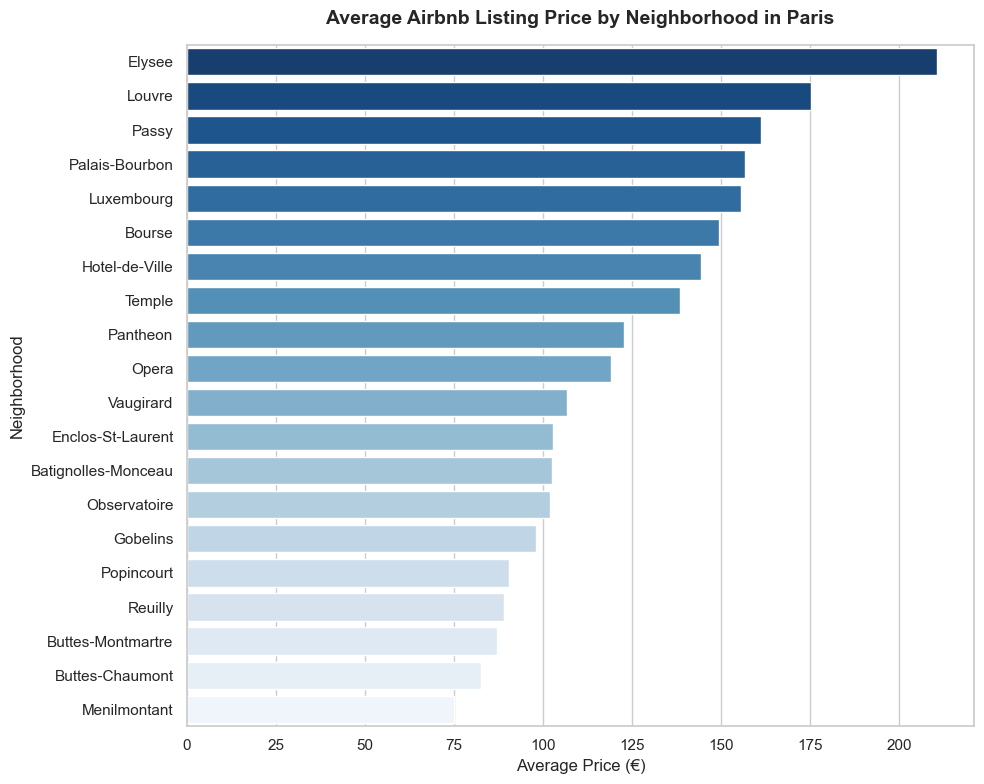

In [89]:
#Create a horizontal bar chart of the average price by neighborhood in Paris, and make sure to add a title and change axis labels as needed

import matplotlib.pyplot as plt
import seaborn as sns


df_plot = paris_listings_neighbourhood.sort_values(by="price", ascending=False)
plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")
ax = sns.barplot(
    data=df_plot,
    x="price",
    y="neighbourhood",
    palette="Blues_r"
)
ax.set_title("Average Airbnb Listing Price by Neighborhood in Paris", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Average Price (€)", fontsize=12)
ax.set_ylabel("Neighborhood", fontsize=12)

plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_17304\1500161946.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


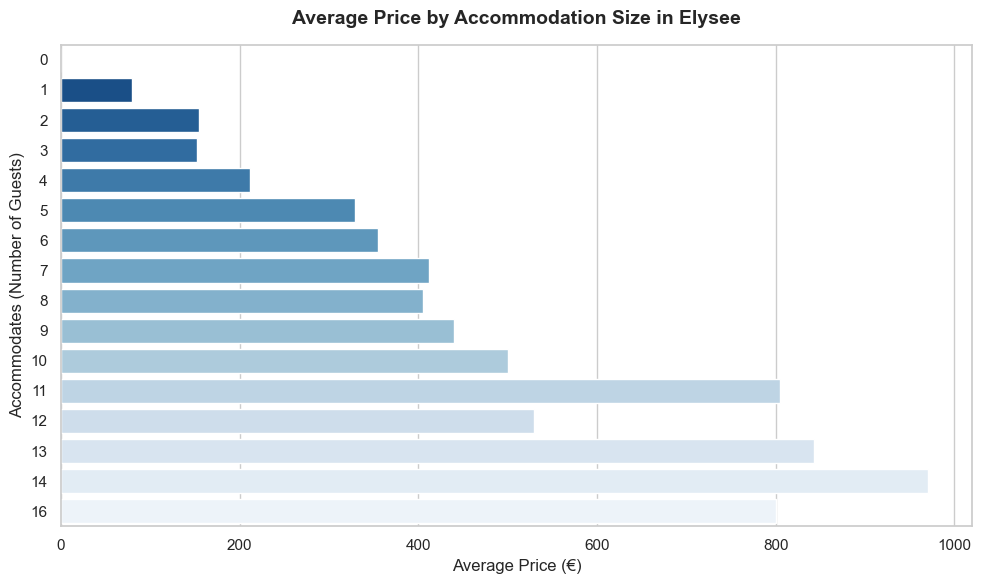

In [91]:
#Create a horizontal bar chart of the average price by ‘accommodates’ in Paris’ most expensive neighborhood, and make sure to add a title and change axis labels as needed

df_plot = paris_listings_accommodations.sort_values(by="accommodates", ascending=True)
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(
    data=df_plot,
    x="price",
    y="accommodates",
    orient="h",
    palette="Blues_r"
)
ax.set_title(
    f"Average Price by Accommodation Size in {most_expensive_neighbourhood}",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Average Price (€)", fontsize=12)
ax.set_ylabel("Accommodates (Number of Guests)", fontsize=12)

plt.tight_layout()
plt.show()


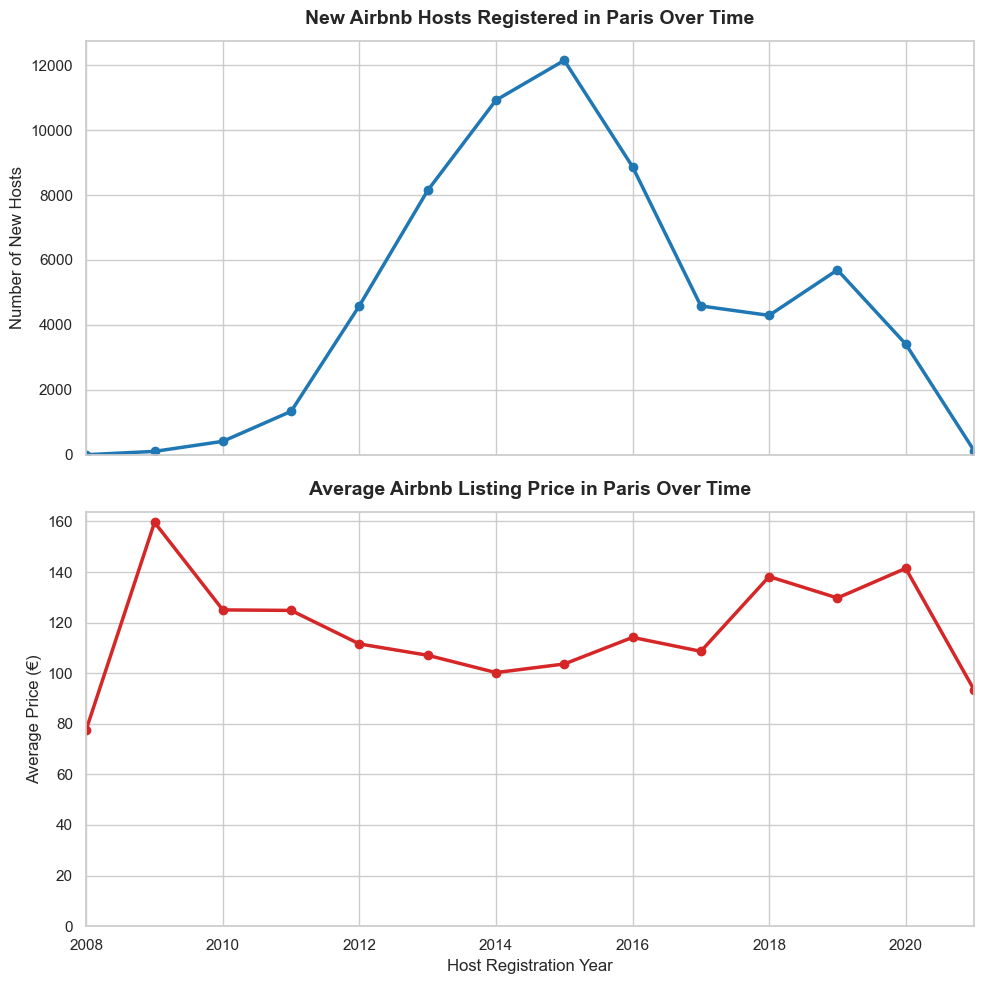

In [111]:
#Create two line charts: one showing the count of new hosts over time, and one showing average price. 
#Set the y-axis limit to 0, add a title, and change axis labels as needed

sns.set_theme(style="whitegrid")

fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(10, 10), sharex=True)

# ------------------------------------------------------------------
# CHART 1: Count of New Hosts Over Time
# ------------------------------------------------------------------
ax1.plot(
    paris_listings_over_time["host_since_year"],
    paris_listings_over_time["new_hosts"],
    marker="o",
    color="#1f77b4",
    linewidth=2.5,
    label="New Hosts"
)

ax1.set_title("New Airbnb Hosts Registered in Paris Over Time", fontsize=14, fontweight="bold", pad=12)
ax1.set_ylabel("Number of New Hosts", fontsize=12)
ax1.set_ylim(bottom=0)  # Set y-axis limit to start at 0

# ------------------------------------------------------------------
# CHART 2: Average Price Over Time
# ------------------------------------------------------------------
ax2.plot(
    paris_listings_over_time["host_since_year"],
    paris_listings_over_time["avg_price"],
    marker="o",
    color="#d62728",
    linewidth=2.5,
    label="Average Price"
)

ax2.set_title("Average Airbnb Listing Price in Paris Over Time", fontsize=14, fontweight="bold", pad=12)
ax2.set_xlabel("Host Registration Year", fontsize=12)
ax2.set_ylabel("Average Price (€)", fontsize=12)

min_year = paris_listings_over_time["host_since_year"].min()
max_year = paris_listings_over_time["host_since_year"].max()

ax1.set_xlim(left=min_year, right=max_year)
ax2.set_xlim(left=min_year, right=max_year)

ax2.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

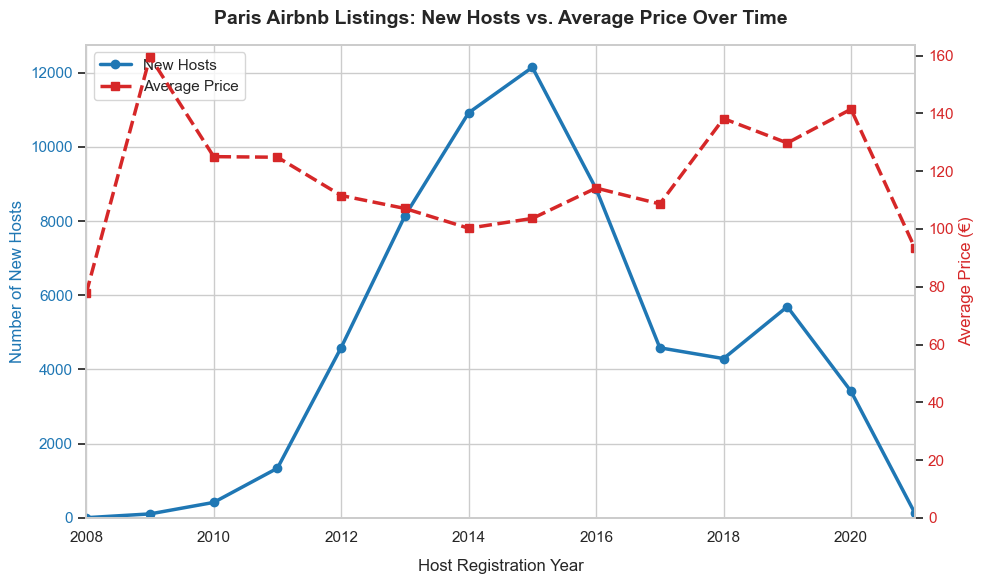

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

fig, ax1 = plt.subplots(figsize=(10, 6))

# ------------------------------------------------------------------
# LINE 1: New Hosts Over Time (Left Y-Axis)
# ------------------------------------------------------------------
color1 = "#1f77b4"  # Blue
line1 = ax1.plot(
    paris_listings_over_time["host_since_year"],
    paris_listings_over_time["new_hosts"],
    color=color1,
    marker="o",
    linewidth=2.5,
    label="New Hosts"
)

ax1.set_xlabel("Host Registration Year", fontsize=12, labelpad=10)
ax1.set_ylabel("Number of New Hosts", fontsize=12, color=color1)
ax1.tick_params(axis="y", labelcolor=color1)
ax1.set_ylim(bottom=0)  # Start Y-axis at 0

# ------------------------------------------------------------------
# LINE 2: Average Price Over Time (Right Y-Axis)
# ------------------------------------------------------------------
ax2 = ax1.twinx()  # Create a second Y-axis sharing the same X-axis

color2 = "#d62728"  # Red
line2 = ax2.plot(
    paris_listings_over_time["host_since_year"],
    paris_listings_over_time["avg_price"],
    color=color2,
    marker="s",
    linewidth=2.5,
    linestyle="--",
    label="Average Price"
)

ax2.set_ylabel("Average Price (€)", fontsize=12, color=color2)
ax2.tick_params(axis="y", labelcolor=color2)
ax2.set_ylim(bottom=0)  # Start secondary Y-axis at 0
ax2.grid(False)         # Turn off secondary grid lines to avoid visual clutter

# ------------------------------------------------------------------
# TITLE & COMBINED LEGEND
# ------------------------------------------------------------------
plt.title(
    "Paris Airbnb Listings: New Hosts vs. Average Price Over Time",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Combine legends from both axes into one legend box
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", frameon=True)

min_year = paris_listings_over_time["host_since_year"].min()
max_year = paris_listings_over_time["host_since_year"].max()

ax1.set_xlim(left=min_year, right=max_year)
ax2.set_xlim(left=min_year, right=max_year)

plt.tight_layout()
plt.show()